
# Teil 2 – Umsatzentwicklung der NANUAG

## Aufgaben a–c: Datenvisualisierung, Regressionsanalyse und Kreuzvalidierung

**Gruppe:** G05

**Ziel:** Untersuchung der Umsatzentwicklung von 1994 bis 2026 und Vergleich verschiedener Regressionsmodelle.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path



### Datenimport

Die Umsatzdaten werden aus der bereitgestellten Textdatei eingelesen. Zunächst wird die Dateistruktur überprüft.

In [3]:

dateipfad = Path("nanuag_umsatz_G05_V01.txt")


df = pd.read_fwf(
    dateipfad,
    header=None,
    names=["Jahr", "Umsatz"],
    decimal=","
)

df.head()

,Jahr,Umsatz
0,1994,17.453939
1,1995,20.815114
2,1996,27.263811
3,1997,35.513772
4,1998,36.085118


In [4]:

df.info()
print("\nFehlende Werte:")
print(df.isna().sum())
print("\nAnzahl der Datensätze:", len(df))
print("\nZeitraum:", df["Jahr"].min(), "-", df["Jahr"].max())

<class 'pandas.DataFrame'>
RangeIndex: 33 entries, 0 to 32
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Jahr    33 non-null     int64  
 1   Umsatz  33 non-null     float64
dtypes: float64(1), int64(1)
memory usage: 660.0 bytes

Fehlende Werte:
Jahr      0
Umsatz    0
dtype: int64

Anzahl der Datensätze: 33

Zeitraum: 1994 - 2026


### Datenprüfung

Der Datensatz enthält 33 Einträge für den Zeitraum von 1994 bis 2026. Die Jahreszahlen liegen als Ganzzahlen (`int64`) und die Umsatzwerte als Fließkommazahlen (`float64`) vor.

Es wurden keine fehlenden Werte festgestellt. Die Daten sind somit für die weitere Analyse geeignet.


## a) Streudiagramm der Umsatzentwicklung

Zur Visualisierung der Umsatzentwicklung der NANUAG von 1994 bis 2026 wird ein Streudiagramm erstellt. Die Jahreszahlen werden auf der x-Achse und der Umsatz in Mio. € auf der y-Achse dargestellt.

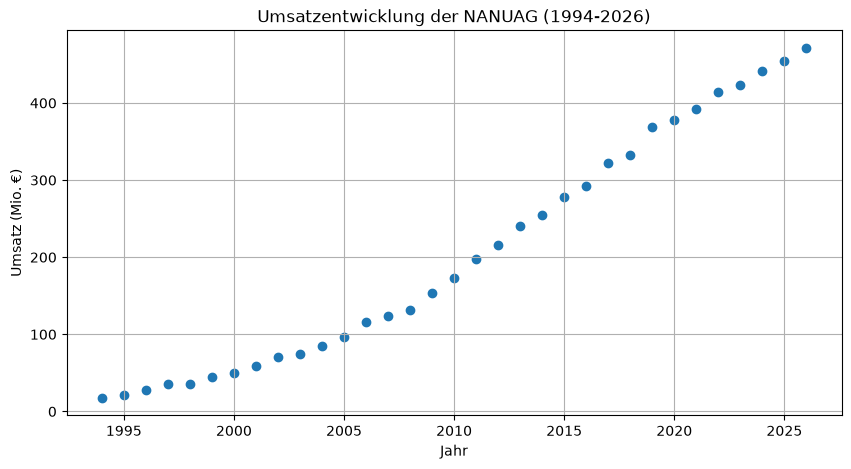

In [5]:

plt.figure(figsize=(10, 5))

plt.scatter(df["Jahr"], df["Umsatz"])

plt.title("Umsatzentwicklung der NANUAG (1994-2026)")
plt.xlabel("Jahr")
plt.ylabel("Umsatz (Mio. €)")

plt.grid(True)
plt.show()


**Interpretation:**

Das Streudiagramm zeigt einen deutlichen Anstieg des Jahresumsatzes zwischen 1994 und 2026. Die Umsatzentwicklung verläuft nicht linear: Während das Wachstum in den ersten Jahren relativ langsam ist, beschleunigt es sich im weiteren Verlauf deutlich. In den letzten Jahren scheint sich das Wachstum wieder etwas zu verlangsamen.

Daher ist zu untersuchen, welches Regressionsmodell diese Entwicklung am besten beschreibt.


## b) Regressionsanalyse

Für die Regressionsanalyse werden die Jahreszahlen standardisiert, um numerische Probleme bei der Berechnung der Polynome zu vermeiden.

Es werden fünf Regressionsmodelle untersucht und anhand des Bestimmtheitsmaßes R² verglichen.

In [6]:

x = df["Jahr"].to_numpy()
y = df["Umsatz"].to_numpy()

# Jahreszahlen standardisieren
x_std = (x - x.mean()) / x.std()

# Erste standardisierte Werte anzeigen
pd.DataFrame({
    "Jahr": x,
    "Jahr_standardisiert": x_std
}).head()

,Jahr,Jahr_standardisiert
0,1994,-1.680336
1,1995,-1.575315
2,1996,-1.470294
3,1997,-1.365273
4,1998,-1.260252


In [7]:

# Lineare Regression
koeff_linear = np.polyfit(x_std, y, 1)

print("Steigung a:", koeff_linear[0])
print("Achsenabschnitt b:", koeff_linear[1])

Steigung a: 146.853830392379
Achsenabschnitt b: 205.85758421212122


In [8]:

# Vorhersagen der linearen Regression
y_linear = np.polyval(koeff_linear, x_std)

# Bestimmtheitsmaß R²
ss_res = np.sum((y - y_linear) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)

r2_linear = 1 - ss_res / ss_tot

print("R² der linearen Regression:", round(r2_linear, 4))

R² der linearen Regression: 0.9703


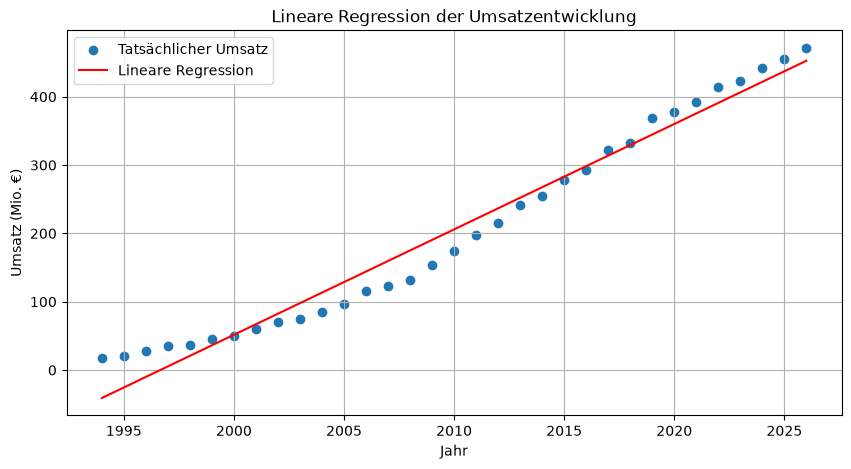

In [9]:

plt.figure(figsize=(10, 5))

plt.scatter(x, y, label="Tatsächlicher Umsatz")
plt.plot(x, y_linear, color="red", label="Lineare Regression")

plt.title("Lineare Regression der Umsatzentwicklung")
plt.xlabel("Jahr")
plt.ylabel("Umsatz (Mio. €)")

plt.legend()
plt.grid(True)
plt.show()


**Lineare Regression – Interpretation:**

Die lineare Regression erreicht ein Bestimmtheitsmaß von R² = 0,9703 und erklärt damit etwa 97,03 % der Umsatzvarianz.

Trotz des hohen R²-Wertes zeigt das Diagramm systematische Abweichungen zwischen den tatsächlichen Umsatzwerten und der Regressionsgeraden. Die lineare Regression bildet den nichtlinearen Verlauf der Umsatzentwicklung daher nur eingeschränkt ab.

In [10]:

# Polynom 2. Grades
koeff_poly2 = np.polyfit(x_std, y, 2)

# Vorhersagen
y_poly2 = np.polyval(koeff_poly2, x_std)

# Bestimmtheitsmaß R²
ss_res_poly2 = np.sum((y - y_poly2) ** 2)
r2_poly2 = 1 - ss_res_poly2 / ss_tot

print("Koeffizienten:", koeff_poly2)
print("R²:", round(r2_poly2, 4))

Koeffizienten: [ 25.13821863 146.85383039 180.71936559]
R²: 0.993


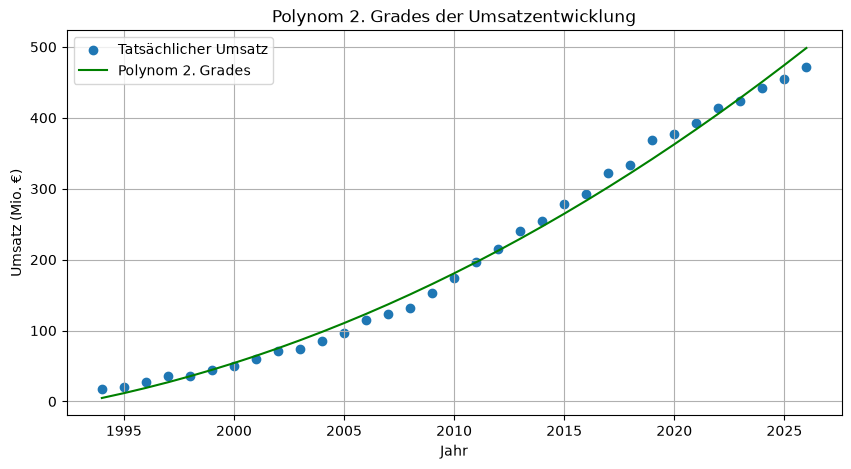

In [12]:
plt.figure(figsize=(10, 5))

plt.scatter(x, y, label="Tatsächlicher Umsatz")
plt.plot(x, y_poly2, color="green", label="Polynom 2. Grades")

plt.title("Polynom 2. Grades der Umsatzentwicklung")
plt.xlabel("Jahr")
plt.ylabel("Umsatz (Mio. €)")

plt.legend()
plt.grid(True)
plt.show()

In [11]:

# Polynom 3. Grades
koeff_poly3 = np.polyfit(x_std, y, 3)

# Vorhersagen
y_poly3 = np.polyval(koeff_poly3, x_std)

# Bestimmtheitsmaß R²
ss_res_poly3 = np.sum((y - y_poly3) ** 2)
r2_poly3 = 1 - ss_res_poly3 / ss_tot

print("Koeffizienten:", koeff_poly3)
print("R²:", round(r2_poly3, 4))

Koeffizienten: [-13.81909522  25.13821863 171.69771848 180.71936559]
R²: 0.9983


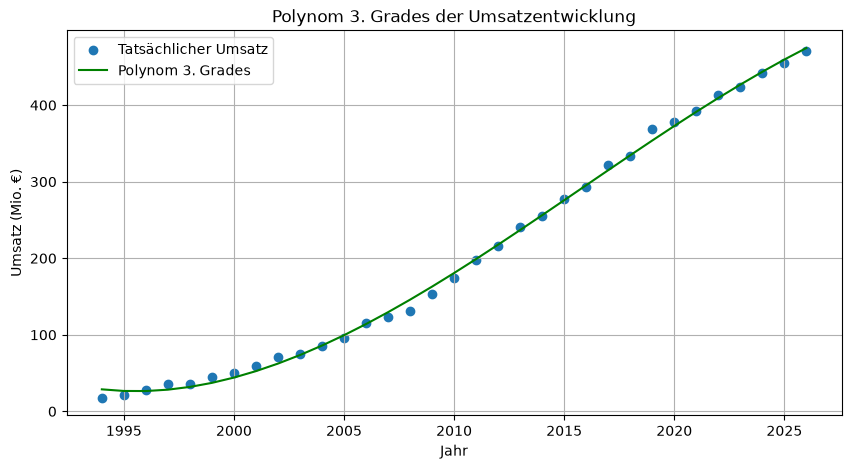

In [13]:

plt.figure(figsize=(10, 5))

plt.scatter(x, y, label="Tatsächlicher Umsatz")
plt.plot(x, y_poly3, color="green", label="Polynom 3. Grades")

plt.title("Polynom 3. Grades der Umsatzentwicklung")
plt.xlabel("Jahr")
plt.ylabel("Umsatz (Mio. €)")

plt.legend()
plt.grid(True)
plt.show()

In [14]:

# Polynom 6. Grades
koeff_poly6 = np.polyfit(x_std, y, 6)

# Vorhersagen
y_poly6 = np.polyval(koeff_poly6, x_std)

# Bestimmtheitsmaß R²
ss_res_poly6 = np.sum((y - y_poly6) ** 2)
r2_poly6 = 1 - ss_res_poly6 / ss_tot

print("Koeffizienten:", koeff_poly6)
print("R²:", round(r2_poly6, 4))

Koeffizienten: [  2.58779755   3.33881378 -17.20739542 -24.88709922  52.73641059
 178.76471787 174.11167481]
R²: 0.9994


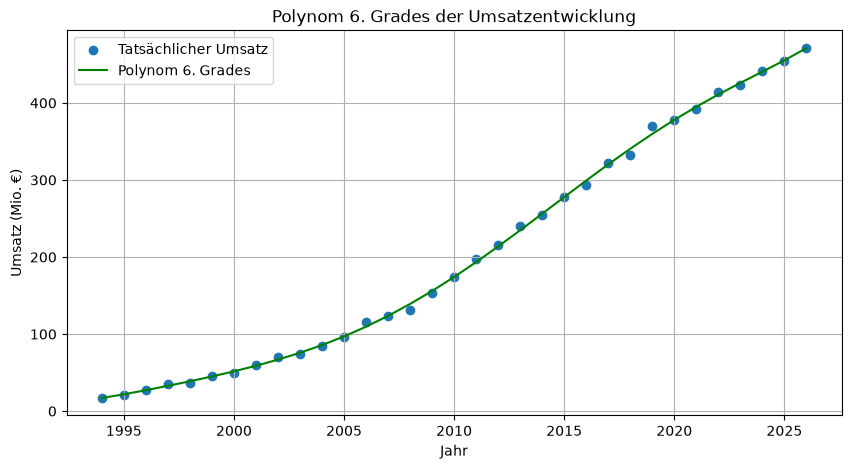

In [15]:

plt.figure(figsize=(10, 5))

plt.scatter(x, y, label="Tatsächlicher Umsatz")
plt.plot(x, y_poly6, color="green", label="Polynom 6. Grades")

plt.title("Polynom 6. Grades der Umsatzentwicklung")
plt.xlabel("Jahr")
plt.ylabel("Umsatz (Mio. €)")

plt.legend()
plt.grid(True)
plt.show()


### Logarithmische Regression

Da die standardisierten Jahreszahlen teilweise negativ sind, wird für die logarithmische Regression eine zusätzliche Verschiebung vorgenommen. Dadurch sind alle Argumente des natürlichen Logarithmus positiv.

In [16]:

# Positive Transformation der Jahreszahlen
x_log = x_std - x_std.min() + 1

# Logarithmische Regression
koeff_log = np.polyfit(np.log(x_log), y, 1)

# Vorhersagen
y_log = np.polyval(koeff_log, np.log(x_log))

# Bestimmtheitsmaß R²
ss_res_log = np.sum((y - y_log) ** 2)
r2_log = 1 - ss_res_log / ss_tot

print("Koeffizienten:", koeff_log)
print("R²:", round(r2_log, 4))

Koeffizienten: [333.27166445 -95.86251336]
R²: 0.8777


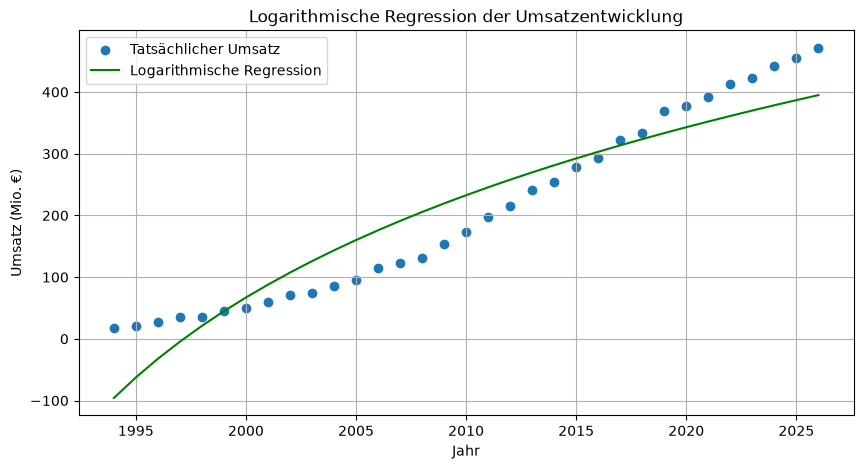

In [17]:

plt.figure(figsize=(10, 5))

plt.scatter(x, y, label="Tatsächlicher Umsatz")
plt.plot(x, y_log, color="green", label="Logarithmische Regression")

plt.title("Logarithmische Regression der Umsatzentwicklung")
plt.xlabel("Jahr")
plt.ylabel("Umsatz (Mio. €)")

plt.legend()
plt.grid(True)
plt.show()


### Vergleich der Regressionsmodelle

Die geschätzten Koeffizienten, Achsenabschnitte und Bestimmtheitsmaße der fünf Regressionsmodelle werden in der folgenden Tabelle zusammengefasst.

In [18]:

ergebnisse = [
    ("Linear", koeff_linear, r2_linear),
    ("Polynom 2. Grades", koeff_poly2, r2_poly2),
    ("Polynom 3. Grades", koeff_poly3, r2_poly3),
    ("Polynom 6. Grades", koeff_poly6, r2_poly6),
    ("Logarithmisch", koeff_log, r2_log)
]

vergleich = pd.DataFrame([
    {
        "Regressionsmodell": name,
        "Koeffizienten": ", ".join(
            f"{wert:.4f}" for wert in koeff[:-1]
        ),
        "Achsenabschnitt": round(koeff[-1], 4),
        "R²": round(r2, 4)
    }
    for name, koeff, r2 in ergebnisse
])

vergleich

,Regressionsmodell,Koeffizienten,Achsenabschnitt,R²
0,Linear,146.8538,205.8576,0.9703
1,Polynom 2. Grades,"25.1382, 146.8538",180.7194,0.9930
2,Polynom 3. Grades,"-13.8191, 25.1382, 171.6977",180.7194,0.9983
3,Polynom 6. Grades,"2.5878, 3.3388, -17.2074, -24.8871, 52.7364, 1...",174.1117,0.9994
4,Logarithmisch,333.2717,-95.8625,0.8777



**Interpretation:**

Das Polynom 6. Grades erreicht mit R² = 0,9994 das höchste Bestimmtheitsmaß, gefolgt vom Polynom 3. Grades mit R² = 0,9983.

Die logarithmische Regression weist mit R² = 0,8777 die geringste Anpassungsgüte auf. Sie unterschätzt insbesondere die Umsatzwerte der letzten Jahre und liefert zu Beginn des Beobachtungszeitraums sogar negative Umsatzschätzungen.

Ein höheres R² bedeutet jedoch nicht automatisch eine bessere Prognosefähigkeit. Daher werden die Modelle in Aufgabe c) anhand von Trainings- und Testdaten überprüft.


## c) Kreuzvalidierung

Zur Überprüfung der Prognosefähigkeit werden die Daten zeitlich aufgeteilt:

- **Trainingsdaten:** 1994–2018 (25 Jahre)
- **Testdaten:** 2019–2026 (8 Jahre)

Alle fünf Regressionsmodelle werden ausschließlich anhand der Trainingsdaten geschätzt. Anschließend wird ihre Anpassungsgüte anhand von R² und RMSE auf den Trainings- und Testdaten verglichen.

In [19]:

# Aufteilung in Trainings- und Testdaten
train = df[df["Jahr"].between(1994, 2018)].copy()
test = df[df["Jahr"].between(2019, 2026)].copy()

print("Trainingsdaten:", len(train))
print("Testdaten:", len(test))

print("\nTrainingszeitraum:")
print(train["Jahr"].min(), "-", train["Jahr"].max())

print("\nTestzeitraum:")
print(test["Jahr"].min(), "-", test["Jahr"].max())

Trainingsdaten: 25
Testdaten: 8

Trainingszeitraum:
1994 - 2018

Testzeitraum:
2019 - 2026


In [20]:

# Jahreszahlen und Umsatzwerte
x_train = train["Jahr"].to_numpy()
y_train = train["Umsatz"].to_numpy()

x_test = test["Jahr"].to_numpy()
y_test = test["Umsatz"].to_numpy()

# Standardisierung anhand der Trainingsdaten
x_mean = x_train.mean()
x_std_train = x_train.std()

x_train_std = (x_train - x_mean) / x_std_train
x_test_std = (x_test - x_mean) / x_std_train

print("Mittelwert:", x_mean)
print("Standardabweichung:", round(x_std_train, 4))

Mittelwert: 2006.0
Standardabweichung: 7.2111


In [22]:
# Lineare Regression – nur Trainingsdaten
koeff_linear_train = np.polyfit(x_train_std, y_train, 1)

# Vorhersagen für Training und Test
y_pred_train = np.polyval(koeff_linear_train, x_train_std)
y_pred_test = np.polyval(koeff_linear_train, x_test_std)

# R² für Trainingsdaten
r2_train = 1 - (
    np.sum((y_train - y_pred_train) ** 2)
    / np.sum((y_train - y_train.mean()) ** 2)
)

# R² für Testdaten
r2_test = 1 - (
    np.sum((y_test - y_pred_test) ** 2)
    / np.sum((y_test - y_test.mean()) ** 2)
)

# RMSE für Testdaten
rmse_test = np.sqrt(np.mean((y_test - y_pred_test) ** 2))

print("R² Training:", round(r2_train, 4))
print("R² Test:", round(r2_test, 4))
print("RMSE Test:", round(rmse_test, 4))

R² Training: 0.9487
R² Test: -1.8469
RMSE Test: 57.986


In [23]:

# Polynom 2. Grades – nur Trainingsdaten
koeff_poly2_train = np.polyfit(x_train_std, y_train, 2)

# Vorhersagen für Training und Test
y_pred_train_poly2 = np.polyval(koeff_poly2_train, x_train_std)
y_pred_test_poly2 = np.polyval(koeff_poly2_train, x_test_std)

# R² für Trainingsdaten
r2_train_poly2 = 1 - (
    np.sum((y_train - y_pred_train_poly2) ** 2)
    / np.sum((y_train - y_train.mean()) ** 2)
)

# R² für Testdaten
r2_test_poly2 = 1 - (
    np.sum((y_test - y_pred_test_poly2) ** 2)
    / np.sum((y_test - y_test.mean()) ** 2)
)

# RMSE für Testdaten
rmse_test_poly2 = np.sqrt(
    np.mean((y_test - y_pred_test_poly2) ** 2)
)

print("R² Training:", round(r2_train_poly2, 4))
print("R² Test:", round(r2_test_poly2, 4))
print("RMSE Test:", round(rmse_test_poly2, 4))

R² Training: 0.9978
R² Test: -1.9914
RMSE Test: 59.4387


In [24]:

# Polynom 3. Grades – nur Trainingsdaten
koeff_poly3_train = np.polyfit(x_train_std, y_train, 3)

# Vorhersagen für Training und Test
y_pred_train_poly3 = np.polyval(koeff_poly3_train, x_train_std)
y_pred_test_poly3 = np.polyval(koeff_poly3_train, x_test_std)

# R² für Trainingsdaten
r2_train_poly3 = 1 - (
    np.sum((y_train - y_pred_train_poly3) ** 2)
    / np.sum((y_train - y_train.mean()) ** 2)
)

# R² für Testdaten
r2_test_poly3 = 1 - (
    np.sum((y_test - y_pred_test_poly3) ** 2)
    / np.sum((y_test - y_test.mean()) ** 2)
)

# RMSE für Testdaten
rmse_test_poly3 = np.sqrt(
    np.mean((y_test - y_pred_test_poly3) ** 2)
)

print("R² Training:", round(r2_train_poly3, 4))
print("R² Test:", round(r2_test_poly3, 4))
print("RMSE Test:", round(rmse_test_poly3, 4))

R² Training: 0.9979
R² Test: -1.1185
RMSE Test: 50.0204


In [25]:

# Polynom 6. Grades – nur Trainingsdaten
koeff_poly6_train = np.polyfit(x_train_std, y_train, 6)

# Vorhersagen für Training und Test
y_pred_train_poly6 = np.polyval(koeff_poly6_train, x_train_std)
y_pred_test_poly6 = np.polyval(koeff_poly6_train, x_test_std)

# R² für Trainingsdaten
r2_train_poly6 = 1 - (
    np.sum((y_train - y_pred_train_poly6) ** 2)
    / np.sum((y_train - y_train.mean()) ** 2)
)

# R² für Testdaten
r2_test_poly6 = 1 - (
    np.sum((y_test - y_pred_test_poly6) ** 2)
    / np.sum((y_test - y_test.mean()) ** 2)
)

# RMSE für Testdaten
rmse_test_poly6 = np.sqrt(
    np.mean((y_test - y_pred_test_poly6) ** 2)
)

print("R² Training:", round(r2_train_poly6, 4))
print("R² Test:", round(r2_test_poly6, 4))
print("RMSE Test:", round(rmse_test_poly6, 4))

R² Training: 0.9991
R² Test: 0.1097
RMSE Test: 32.4273


In [26]:

# Logarithmische Regression – nur Trainingsdaten

# Positive Transformation anhand der Trainingsdaten
x_log_train = x_train_std - x_train_std.min() + 1
x_log_test = x_test_std - x_train_std.min() + 1

# Regression nur auf Trainingsdaten
koeff_log_train = np.polyfit(np.log(x_log_train), y_train, 1)

# Vorhersagen für Training und Test
y_pred_train_log = np.polyval(koeff_log_train, np.log(x_log_train))
y_pred_test_log = np.polyval(koeff_log_train, np.log(x_log_test))

# R² für Trainingsdaten
r2_train_log = 1 - (
    np.sum((y_train - y_pred_train_log) ** 2)
    / np.sum((y_train - y_train.mean()) ** 2)
)

# R² für Testdaten
r2_test_log = 1 - (
    np.sum((y_test - y_pred_test_log) ** 2)
    / np.sum((y_test - y_test.mean()) ** 2)
)

# RMSE für Testdaten
rmse_test_log = np.sqrt(
    np.mean((y_test - y_pred_test_log) ** 2)
)

print("R² Training:", round(r2_train_log, 4))
print("R² Test:", round(r2_test_log, 4))
print("RMSE Test:", round(rmse_test_log, 4))

R² Training: 0.8379
R² Test: -13.4099
RMSE Test: 130.4562



### Vergleich der Modelle auf Trainings- und Testdaten

Die folgende Tabelle zeigt die Bestimmtheitsmaße R² für die Trainings- und Testdaten sowie den RMSE auf den Testdaten.

In [27]:

# Vergleich aller fünf Modelle
vergleich_cv = pd.DataFrame({
    "Regressionsmodell": [
        "Linear",
        "Polynom 2. Grades",
        "Polynom 3. Grades",
        "Polynom 6. Grades",
        "Logarithmisch"
    ],
    "R² Training": [
        r2_train,
        r2_train_poly2,
        r2_train_poly3,
        r2_train_poly6,
        r2_train_log
    ],
    "R² Test": [
        r2_test,
        r2_test_poly2,
        r2_test_poly3,
        r2_test_poly6,
        r2_test_log
    ],
    "RMSE Test (Mio. €)": [
        rmse_test,
        rmse_test_poly2,
        rmse_test_poly3,
        rmse_test_poly6,
        rmse_test_log
    ]
})

vergleich_cv.round(4)

,Regressionsmodell,R² Training,R² Test,RMSE Test (Mio. €)
0,Linear,0.9487,-1.8469,57.9860
1,Polynom 2. Grades,0.9978,-1.9914,59.4387
2,Polynom 3. Grades,0.9979,-1.1185,50.0204
3,Polynom 6. Grades,0.9991,0.1097,32.4273
4,Logarithmisch,0.8379,-13.4099,130.4562



### Interpretation der Kreuzvalidierung

Die Ergebnisse zeigen, dass sich die Prognosegüte aller fünf Modelle auf den Testdaten deutlich verschlechtert.

Die **logarithmische Regression** weist die stärkste Verschlechterung auf. Ihre Annahme eines abnehmenden Wachstums passt nicht zur tatsächlichen Umsatzentwicklung.

Auch die lineare und die quadratische Regression liefern ungenaue Prognosen. Das Polynom 3. Grades schneidet etwas besser ab.

Das **Polynom 6. Grades** erreicht den niedrigsten RMSE und als einziges Modell ein positives R² auf den Testdaten. Es zeigt damit die beste Prognoseleistung innerhalb des untersuchten Zeitraums.

Die Ergebnisse verdeutlichen das **Extrapolationsproblem**: Eine gute Anpassung an die Trainingsdaten garantiert keine zuverlässigen Vorhersagen für spätere Jahre. Insbesondere bei komplexen Modellen besteht zusätzlich das Risiko von Overfitting.